<a href="https://colab.research.google.com/github/mpino3531-art/FACTURA/blob/main/Copia_de_Equipo_7_Series_Temporales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Equipo 7 · Drawdown: medir caídas desde máximos anteriores

**Curso:** Series temporales financieras  
**Fuente de datos:** Yahoo Finance mediante `yfinance`  
**Activo principal:** AAPL (Apple Inc.)  
**Período de trabajo:** enero de 2020 a diciembre de 2025

## Misión del equipo
**Pregunta central:** ¿Qué tan lejos estuvo el precio de AAPL de su máximo acumulado hasta cada fecha?

### Objetivos
- Explicar máximo acumulado y drawdown.
- Calcular caída porcentual desde el máximo previo.
- Distinguir drawdown de rendimiento diario.

### Consulta conceptual obligatoria
Antes de completar el análisis, consulten fuentes confiables y respondan con sus propias palabras:
- ¿Qué es un drawdown?
- ¿Cómo se calcula el máximo acumulado?
- ¿Qué limitaciones tiene usar el drawdown histórico para anticipar pérdidas futuras?

**Importante:** este notebook es una plantilla de trabajo. Completen los espacios, expliquen el código con sus palabras y no se limiten a ejecutar las celdas. Citen las fuentes consultadas. Los resultados pueden variar según los datos disponibles al descargar.


## 1. Investigación previa
- Definición de drawdown: es la caída porcentual del precio de un activo financiero con respecto al máximo que había alcanzado hasta una fecha determinada. Permite identificar cuánto ha retrocedido un activo desde su máximo anterior, aunque no necesariamente indica cuánto dinero pierde un inversionista que compró en una fecha específica.

Por ejemplo, si una acción alcanzó un precio máximo de 200 y luego bajó a $150, el drawdown es del -25 %.

- Fórmula usando precio y máximo acumulado: La fórmula del drawdown porcentual usando el precio actual y el máximo acumulado es:

Drawdown (%) = [(Precio actual / Máximo acumulado) - 1] × 100

Donde:

(P_t\): precio de la acción en la fecha actual.
(M_t\): máximo acumulado del precio hasta esa fecha.

Ejemplo: si el precio actual de una acción es 150 y su máximo acumulado es 200:
Drawdown = (150 / 200 - 1) × 100 = -25%

- Diferencia entre una caída diaria y un drawdown:

Caída diaria: compara el precio de un día con el precio del día bursátil anterior.

Drawdown: compara el precio actual con el máximo acumulado anterior o hasta esa fecha.

Una acción puede caer un 2 % en un solo día y, aun así, tener un drawdown del 20 % si ya venía descendiendo desde un máximo anterior.

In [4]:
!pip -q install yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TICKER = "AAPL"
START = "2020-01-01"
END = "2026-01-01"

datos = yf.download(
    TICKER,
    start=START,
    end=END,
    auto_adjust=True,
    progress=False
)

# Algunas versiones de yfinance pueden devolver columnas MultiIndex.
if isinstance(datos.columns, pd.MultiIndex):
    datos.columns = datos.columns.get_level_values(0)

datos = datos.dropna(how="all")
datos.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568909,72.326874,71.345130,71.501534,146322800
2020-01-06,72.139183,72.177684,70.442784,70.693036,118387200
2020-01-07,71.799919,72.403881,71.580950,72.148820,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200


## 2. Calcular máximo acumulado y drawdown
El máximo acumulado es el precio máximo observado desde el inicio del período hasta cada fecha. El drawdown mide cuánto está el precio por debajo de ese máximo, en porcentaje.

In [2]:
datos["Maximo_acumulado"] = datos["Close"].cummax()
datos["Drawdown_pct"] = (datos["Close"] / datos["Maximo_acumulado"] - 1) * 100
print("Peor drawdown observado:", round(datos["Drawdown_pct"].min(), 2), "%")
fecha_peor = datos["Drawdown_pct"].idxmin()
print("Fecha del peor drawdown:", fecha_peor.date())
display(datos.loc[[fecha_peor], ["Close", "Maximo_acumulado", "Drawdown_pct"]].round(2))

Peor drawdown observado: -33.36 %
Fecha del peor drawdown: 2025-04-08


Price,Close,Maximo_acumulado,Drawdown_pct
Date,,,
2025-04-08,171.37,257.15,-33.36


El máximo acumulado permite identificar el precio más alto alcanzado por la acción AAPL desde el inicio del período de estudio hasta cada fecha. A partir de este valor se calcula el drawdown, que representa la caída porcentual del precio respecto a su máximo acumulado. Finalmente, se identifica el peor drawdown observado y la fecha en que ocurrió, lo que permite reconocer el momento de mayor caída relativa durante el período analizado.

## 3. Graficar el drawdown
El eje vertical debe estar en porcentaje. Los valores negativos representan precios por debajo de su máximo acumulado; cero significa que el precio está en un máximo acumulado.

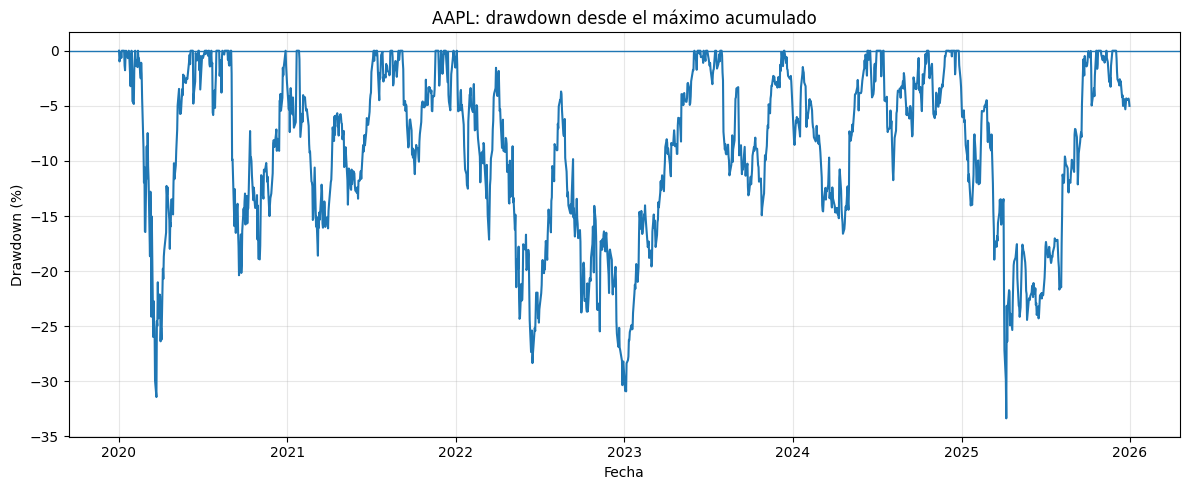

In [9]:
# Aseguramos que existan las columnas de drawdown antes de graficar
if "Drawdown_pct" not in datos.columns:
    datos["Maximo_acumulado"] = datos["Close"].cummax()
    datos["Drawdown_pct"] = (datos["Close"] / datos["Maximo_acumulado"] - 1) * 100

plt.figure(figsize=(12,5))
plt.plot(datos.index, datos["Drawdown_pct"])
plt.axhline(0, linewidth=1)
plt.title("AAPL: drawdown desde el máximo acumulado")
plt.xlabel("Fecha")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

El gráfico permite observar las caídas porcentuales del precio de AAPL con respecto a su máximo acumulado durante el período de estudio. Los valores negativos indican que el precio se encuentra por debajo de su máximo anterior, mientras que el cero representa la recuperación hasta un máximo acumulado. Los puntos más negativos permiten identificar los períodos de mayor caída relativa. La validación incorporada al código permite comprobar si el indicador ya fue calculado antes de generar el gráfico.

## 4. Interpretación
1. ¿Cómo se interpreta un drawdown de −15 %?

Un drawdown de −15 % significa que el precio de la acción está un 15 % por debajo de su máximo acumulado. Por ejemplo, si AAPL alcanzó un máximo de  200, una caída hasta 170 representa un drawdown del −15 %. Esto permite medir cuánto ha retrocedido el precio desde su máximo anterior.

2. ¿Cuál fue la caída más profunda observada en el período?

La caída más profunda corresponde al valor más negativo de la columna Drawdown_pct durante el período comprendido entre enero de 2020 y diciembre de 2025. Para identificarla, se utiliza min(), que permite obtener el drawdown mínimo, e idxmin(), que identifica la fecha en que ocurrió.

3. ¿Por qué un drawdown no es lo mismo que el rendimiento de un solo día?

El rendimiento diario mide la variación porcentual del precio entre dos sesiones bursátiles consecutivas. En cambio, el drawdown compara el precio actual con el máximo acumulado hasta esa fecha. Por lo tanto, el rendimiento diario permite observar los cambios de un día a otro, mientras que el drawdown permite identificar la profundidad de las caídas respecto a máximos anteriores.

4. ¿Qué limitación tiene medir el riesgo usando solo el peor drawdown pasado?

La principal limitación es que el peor drawdown histórico solo muestra lo ocurrido en el período analizado y no garantiza que las pérdidas futuras sean iguales o menores. Las condiciones del mercado pueden cambiar y generar caídas más profundas. Por eso, es recomendable complementar este indicador con otras medidas de riesgo, como la volatilidad y los rendimientos históricos.

**Conclusión financiera:**

El análisis del drawdown de las acciones de Apple (AAPL) entre enero de 2020 y diciembre de 2025 permite comprender las caídas del precio con respecto a sus máximos acumulados. Mediante Python y las bibliotecas pandas y matplotlib, fue posible calcular este indicador y representarlo gráficamente para identificar los períodos de mayor caída relativa.

Este análisis demuestra que el drawdown es útil para evaluar la magnitud de los retrocesos que ha experimentado una acción y comprender mejor su comportamiento histórico. Sin embargo, no permite predecir con certeza las pérdidas futuras, por lo que debe complementarse con otros indicadores financieros antes de tomar decisiones de inversión.

## 5. Fuentes y participación
Fuentes: **Yahoo Finance. Datos históricos de Apple Inc. (AAPL). Consultar los datos históricos.



pandas. Documentación oficial de Series.cummax(), función utilizada para calcular el máximo acumulado. Consultar documentación.



yfinance. Documentación de la función download(), utilizada para descargar los precios históricos. Consultar documentación.



O'Connell, R. Maximum Drawdown: What It Is, How to Calculate It, and Why It Matters. Consultar explicación del drawdown**.

Aportes de integrantes: **Maira Pino: Investigación de los conceptos de máximo acumulado y drawdown, y consulta de las fuentes de información.

Xiomara: Desarrollo y ejecución del código en Python para calcular el drawdown y generar las gráficas.

Millerlay: Interpretación de los resultados, análisis financiero y elaboración de las conclusiones.**.